# Timing, decoherence, and resource estimates

This notebook explores a simple Zeno experiment with a 50 kHz drive, so a half-turn takes 10 μs. The example parameters are $T_1=115$ μs, $T_2=129$ μs, a 180 ns recording gate, and gate fidelity 0.9977. They are illustrative benchmarks, not a calibration for a named device.

The dynamics calculation follows the system qubit while the memory records are unread. It does not simulate coherent schedule control or memory parity. A separate resource plot counts the qubits and settings needed for full tomography if an additional history-clock register is encoded in qubits.

Run from top to bottom. The five figure pairs are saved in the repository root.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Choose a 50 kHz drive.
f_R_MHz = 0.05                 # 50 kHz = 0.05 cycles/us
Omega = 2*np.pi*f_R_MHz       # rad/us
T_pi = np.pi/Omega            # us

# Example coherence times and gate values.
T1_us = 115.0
T2_us = 129.0
cnot_time_us = 0.180
cnot_fidelity = 0.9977

print(f'Omega/2pi = {f_R_MHz*1e3:.0f} kHz')
print(f'pi-rotation time = {T_pi:.2f} us')
print(f'T1 = {T1_us:.1f} us, T2 = {T2_us:.1f} us')
print(f'CNOT time = {cnot_time_us*1e3:.0f} ns, fidelity = {cnot_fidelity:.4f}')

Omega/2pi = 50 kHz
pi-rotation time = 10.00 us
T1 = 115.0 us, T2 = 129.0 us
CNOT time = 180 ns, fidelity = 0.9977


## Describe the system evolution

The Bloch equations track the system during the drive and waiting periods. Each ideal unread record removes its X and Y coherence.

In [2]:
def p_baseline(T):
    return np.cos(Omega*T/2.0)**2

def p_zeno_ideal(T, N):
    # N equally spaced unread measurement interactions over [0,T]
    return 0.5*(1.0 + np.cos(Omega*T/N)**N)

def p_selective_survival(T, N):
    return np.cos(Omega*T/(2.0*N))**(2*N)

def bloch_rhs(t, v, omega_drive):
    # Drive, relaxation, and coherence loss; z=+1 is the zero state.
    x, y, z = v
    dx = -x/T2_us
    dy = -omega_drive*z - y/T2_us
    dz = omega_drive*y - (z - 1.0)/T1_us
    return np.array([dx, dy, dz])

def propagate(v, duration_us, omega_drive):
    if duration_us <= 0:
        return np.array(v, dtype=float)
    sol = solve_ivp(
        lambda t, y: bloch_rhs(t, y, omega_drive),
        (0.0, duration_us), np.array(v, dtype=float),
        t_eval=[duration_us], rtol=1e-9, atol=1e-11
    )
    return sol.y[:, -1]

def p_no_memory_noisy(T):
    v = propagate([0.0, 0.0, 1.0], T, Omega)
    return 0.5*(1.0 + v[2])

def p_zeno_noisy(T, N, include_gate_duration=True):
    # Let S decay between ideal records. Optionally add gate waiting time.
    v = np.array([0.0, 0.0, 1.0])
    dt = T/N
    for _ in range(N):
        v = propagate(v, dt, Omega)
        if include_gate_duration:
            v = propagate(v, cnot_time_us, 0.0)
        # unread ideal projective measurement in the Z basis
        v[0] = 0.0
        v[1] = 0.0
    return 0.5*(1.0 + v[2])

## Figure 1. Add more records

For each final time $T$, we space the $N$ records evenly. Without records, the system undergoes ordinary Rabi oscillation. More frequent records keep it closer to its starting state. These curves are ideal and use all shots.

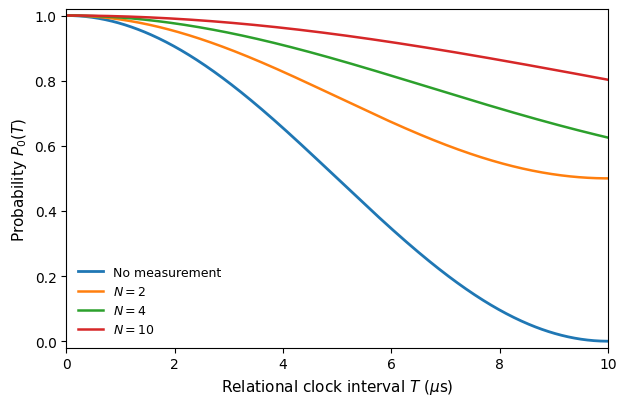

In [3]:
T = np.linspace(0.0, T_pi, 500)
N_values = [2, 4, 10]

plt.figure(figsize=(6.4, 4.2))
plt.plot(T, p_baseline(T), linewidth=2.0, label='No measurement')
for N in N_values:
    plt.plot(T, p_zeno_ideal(T, N), linewidth=1.8, label=fr'$N={N}$')
plt.xlabel(r'Relational clock interval $T$ ($\mu$s)')
plt.ylabel(r'Probability $P_0(T)$')
plt.xlim(0, T_pi)
plt.ylim(-0.02, 1.02)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('fig1_relational_zeno_dynamics.pdf', bbox_inches='tight')
plt.savefig('fig1_relational_zeno_dynamics.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure 2. Include system decoherence

At 10 μs, the ideal system without records has flipped from zero to one. We compare ideal recording with system relaxation and dephasing. Each recording also adds 180 ns of decay with the drive off.

The recording itself remains an ideal unread Z measurement. This is a simple timing model, not a simulation of the gate pulse.

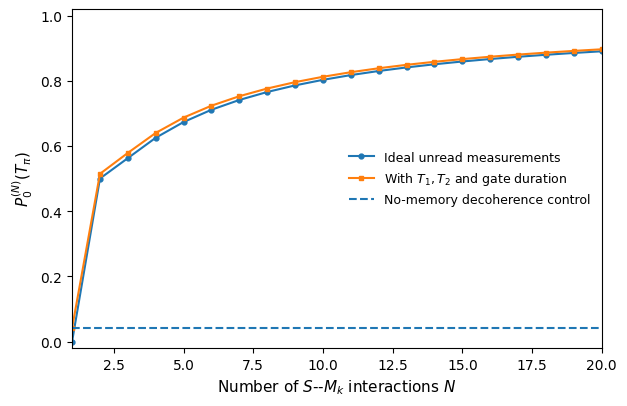

N= 4: ideal P0=0.625, noisy P0=0.640, sequence duration~10.72 us, F_CNOT^N~0.991
N=10: ideal P0=0.803, noisy P0=0.812, sequence duration~11.80 us, F_CNOT^N~0.977
N=20: ideal P0=0.890, noisy P0=0.896, sequence duration~13.60 us, F_CNOT^N~0.955
No-memory noisy control at T_pi: P0=0.040


In [4]:
N = np.arange(1, 21)
p_ideal = np.array([p_zeno_ideal(T_pi, int(n)) for n in N])
p_noisy = np.array([p_zeno_noisy(T_pi, int(n), include_gate_duration=True) for n in N])
p_control = p_no_memory_noisy(T_pi)

plt.figure(figsize=(6.4, 4.2))
plt.plot(N, p_ideal, marker='o', markersize=3.5, label='Ideal unread measurements')
plt.plot(N, p_noisy, marker='s', markersize=3.5, label=r'With $T_1,T_2$ and gate duration')
plt.axhline(p_control, linestyle='--', linewidth=1.5, label='No-memory decoherence control')
plt.xlabel(r'Number of $S$--$M_k$ interactions $N$')
plt.ylabel(r'$P_0^{(N)}(T_\pi)$')
plt.xlim(1, 20)
plt.ylim(-0.02, 1.02)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('fig2_zeno_realistic_scaling.pdf', bbox_inches='tight')
plt.savefig('fig2_zeno_realistic_scaling.png', dpi=300, bbox_inches='tight')
plt.show()

for n in [4, 10, 20]:
    print(f'N={n:2d}: ideal P0={p_zeno_ideal(T_pi,n):.3f}, noisy P0={p_zeno_noisy(T_pi,n):.3f}, '
          f'sequence duration~{T_pi+n*cnot_time_us:.2f} us, F_CNOT^N~{cnot_fidelity**n:.3f}')
print(f'No-memory noisy control at T_pi: P0={p_control:.3f}')

## Figure 3. Compare the duration with the lifetimes

The sequence lasts 10 μs plus 180 ns for each recording gate. We divide that duration by the example $T_1$ and $T_2$. These ratios show the time spent, not a direct error probability.

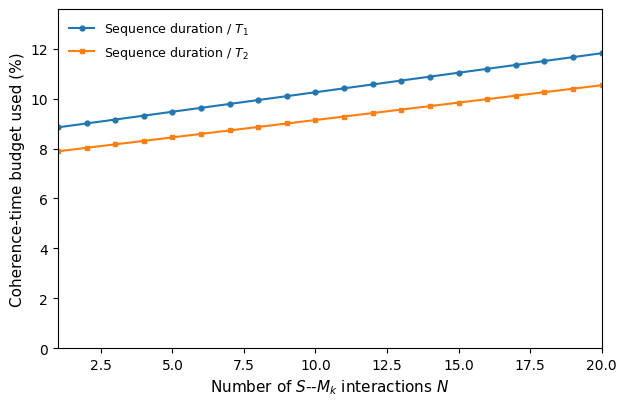

In [5]:
N = np.arange(1, 21)
sequence_duration = T_pi + N*cnot_time_us
fraction_T1 = 100.0*sequence_duration/T1_us
fraction_T2 = 100.0*sequence_duration/T2_us

plt.figure(figsize=(6.4, 4.2))
plt.plot(N, fraction_T1, marker='o', markersize=3.5, label=r'Sequence duration / $T_1$')
plt.plot(N, fraction_T2, marker='s', markersize=3.5, label=r'Sequence duration / $T_2$')
plt.xlabel(r'Number of $S$--$M_k$ interactions $N$')
plt.ylabel('Coherence-time budget used (%)')
plt.xlim(1, 20)
plt.ylim(0, max(fraction_T1)*1.15)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('fig3_coherence_budget.pdf', bbox_inches='tight')
plt.savefig('fig3_coherence_budget.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure 4. Estimate accumulated gate loss

The curve is the simple product $F_{\mathrm{CNOT}}^N$. It is a rough budget, not a full circuit fidelity: it leaves out correlated errors, preparation and readout errors, and memory or schedule-qubit noise.

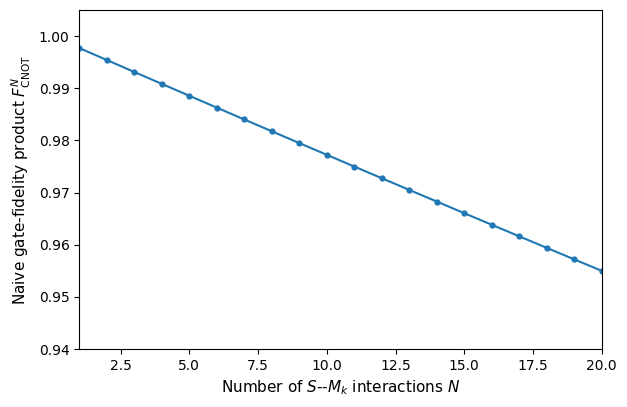

In [6]:
N = np.arange(1, 21)
cumulative_gate_budget = cnot_fidelity**N

plt.figure(figsize=(6.4, 4.2))
plt.plot(N, cumulative_gate_budget, marker='o', markersize=3.5)
plt.xlabel(r'Number of $S$--$M_k$ interactions $N$')
plt.ylabel(r'Naive gate-fidelity product $F_{\mathrm{CNOT}}^N$')
plt.xlim(1, 20)
plt.ylim(0.94, 1.005)
plt.tight_layout()
plt.savefig('fig4_cumulative_gate_budget.pdf', bbox_inches='tight')
plt.savefig('fig4_cumulative_gate_budget.png', dpi=300, bbox_inches='tight')
plt.show()

## Figure 5. Count full-tomography settings

Encoding $N+1$ history-clock readings takes $q_C=\lceil\log_2(N+1)\rceil$ qubits. Adding one system and $N$ memories gives $q_{\mathrm{tot}}=q_C+1+N$. Full local Pauli tomography then uses $3^{q_{\mathrm{tot}}}$ measurement settings.

That grows quickly. Measuring a few specific observables, such as parity, is cheaper. This extra history-clock register is not the single schedule qubit in the circuit notebooks.

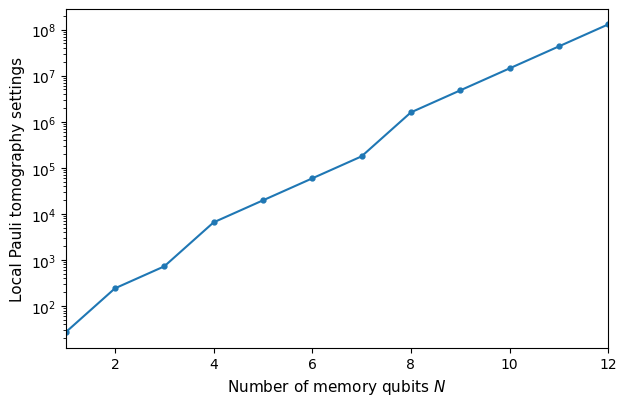

N=2: clock qubits=2, total qubits=5, 3^q settings=243
N=4: clock qubits=3, total qubits=8, 3^q settings=6,561
N=6: clock qubits=3, total qubits=10, 3^q settings=59,049
N=10: clock qubits=4, total qubits=15, 3^q settings=14,348,907


In [7]:
N = np.arange(1, 13)
q_clock = np.ceil(np.log2(N + 1)).astype(int)
q_total = N + 1 + q_clock
tomography_settings = 3**q_total

plt.figure(figsize=(6.4, 4.2))
plt.plot(N, tomography_settings, marker='o', markersize=3.5)
plt.yscale('log')
plt.xlabel(r'Number of memory qubits $N$')
plt.ylabel('Local Pauli tomography settings')
plt.xlim(1, 12)
plt.tight_layout()
plt.savefig('fig5_tomography_scaling.pdf', bbox_inches='tight')
plt.savefig('fig5_tomography_scaling.png', dpi=300, bbox_inches='tight')
plt.show()

for n in [2, 4, 6, 10]:
    qc = int(np.ceil(np.log2(n+1)))
    qt = n + 1 + qc
    print(f'N={n}: clock qubits={qc}, total qubits={qt}, 3^q settings={3**qt:,}')

## Limits of these estimates

The recording gates are ideal apart from extra decay time. The gate-fidelity product is shown separately; it is not part of the dynamics model. We do not simulate clock imperfections, correlated noise, or an autonomous clock-controlled implementation.

For four ideal records at the half-turn time, $P_0=0.625$, compared with zero without records. This illustrates Zeno suppression under the stated assumptions.